# Did the Body Clock Shift Replicate?

Follow-up to `01_rr1_liver_analysis.ipynb`. That notebook found the liver body clock shifted in RR-1 mice after 37 days in space. One study is one study, so this one pulls four more Rodent Research liver studies from NASA OSDR and checks whether the same shift shows up.

| Mission | OSD | Mice | Where they were euthanized |
|---|---|---|---|
| RR-1 | 48 | female C57BL/6J, 37 days | on the ISS |
| RR-6 | 245 | female C57BL/6NTac, ~60 days | on the ISS |
| RR-3 | 137 | female BALB/c, 39–42 days | on the ISS |
| RR-9 | 242 | male C57BL/6J, 33 days | on Earth, after splashdown |
| RR-23 | 463 | male C57BL/6J, 38 days | on Earth, after splashdown |

Run the cells in order, top to bottom.

# Cell 1  //  Setup

Same libraries, colors and file finder as the first notebook.

In [1]:
import requests, io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

INK, PINK, MAUVE, BLUSH = "#3A1C2B", "#E8447A", "#8C6B76", "#FCE4EC"

def find_files(obj):
    out = []
    if isinstance(obj, dict):
        if "file_name" in obj:
            out.append(obj)
        for v in obj.values():
            out += find_files(v)
    elif isinstance(obj, list):
        for v in obj:
            out += find_files(v)
    return out

# Cell 2  //  Load Every Mission

For each study this finds the differential expression file, picks the Space Flight vs. Ground Control comparison (preferring one where both groups were dissected the same way), and flips the sign like the first notebook so positive always means higher in space. It prints which column it used, so you can check it.

Takes a few minutes, the files are about 35 MB each.

In [2]:
# first three: mice euthanized on the ISS. last two: flown home alive, dissected days later on Earth
MISSIONS = {"48": "RR-1", "245": "RR-6", "137": "RR-3", "242": "RR-9", "463": "RR-23"}

def groups(col):
    return col.split("_", 1)[1][1:-1].split(")v(")

def load_mission(osd):
    meta = requests.get(f"https://osdr.nasa.gov/osdr/data/osd/files/{osd}").json()
    dge = [f for f in find_files(meta)
           if "differential_expression" in f["file_name"].lower()
           and f["file_name"].lower().endswith(".csv")]
    target = sorted(dge, key=lambda f: "rrnarm" not in f["file_name"].lower())[0]
    df = pd.read_csv(io.StringIO(requests.get("https://osdr.nasa.gov" + target["remote_url"]).text))

    # only Space Flight vs Ground Control, prefer both sides dissected the same way (carcass)
    pairs = [c for c in df.columns if c.startswith("Log2fc")
             and {g.split(" & ")[0] for g in groups(c)} == {"Space Flight", "Ground Control"}]
    fc_col = max(pairs, key=lambda c: all("Carcass" in g for g in groups(c)))
    comparison = fc_col.split("_", 1)[1]
    p_col = "Adj.p.value_" + comparison
    flip = groups(fc_col)[0].startswith("Ground")

    d = df[["SYMBOL", fc_col, p_col]].dropna().copy()
    d.columns = ["gene", "fc", "padj"]
    if flip:
        d["fc"] = -d["fc"]
    print(f"OSD-{osd} {MISSIONS[osd]:<6} using {comparison}  (flipped: {flip})")
    return d.drop_duplicates("gene").set_index("gene")

runs = {MISSIONS[o]: load_mission(o) for o in MISSIONS}
print()
for name, m in runs.items():
    n_up = ((m["fc"] > 1) & (m["padj"] < 0.05)).sum()
    n_down = ((m["fc"] < -1) & (m["padj"] < 0.05)).sum()
    print(f"{name:<6} genes tested: {len(m):>6}   up: {n_up:>4}   down: {n_down:>4}")

OSD-48 RR-1   using (Ground Control & Carcass)v(Space Flight & Carcass)  (flipped: True)


OSD-245 RR-6   using (Ground Control & ~60 day & On Earth & Carcass)v(Space Flight & ~60 day & On ISS & Carcass)  (flipped: True)


OSD-137 RR-3   using (Ground Control)v(Space Flight)  (flipped: True)


OSD-242 RR-9   using (Ground Control)v(Space Flight)  (flipped: True)


OSD-463 RR-23  using (Ground Control)v(Space Flight)  (flipped: True)

RR-1   genes tested:  13256   up:  112   down:   72
RR-6   genes tested:  16818   up:  250   down:  198
RR-3   genes tested:  17508   up:    0   down:    0
RR-9   genes tested:  14707   up:   55   down:  230
RR-23  genes tested:  16120   up:  312   down:  376


# Cell 3  //  Clock Genes Across Missions

Same clock genes as the first notebook, one column per mission. `*` means adjusted p under 0.05.

In [3]:
clock = ["Npas2", "Bmal1", "Clock", "Cry1", "Per1", "Per3", "Nr1d1", "Nr1d2", "Tef", "Dbp"]
fc = pd.DataFrame({name: m["fc"] for name, m in runs.items()}).reindex(clock)
padj = pd.DataFrame({name: m["padj"] for name, m in runs.items()}).reindex(clock)

def cell(f, p):
    if pd.isna(f):
        return "   -   "
    arrow = "↑" if f > 0 else "↓"
    star = "*" if p < 0.05 else " "
    return f"{2 ** abs(f):5.1f}x{arrow}{star}"

print("fold change in space vs. ground   (* = adjusted p < 0.05)\n")
print(f"{'gene':<7}" + "".join(f"{n:>10}" for n in fc.columns))
for g in clock:
    print(f"{g:<7}" + "".join(f"{cell(fc.loc[g, n], padj.loc[g, n]):>10}" for n in fc.columns))

fold change in space vs. ground   (* = adjusted p < 0.05)

gene         RR-1      RR-6      RR-3      RR-9     RR-23
Npas2     14.6x↑*    5.5x↑*    1.0x↑     2.6x↓     3.2x↑ 
Bmal1      5.2x↑*    8.7x↑*    1.1x↓     1.0x↓     1.4x↓ 
Clock      1.4x↑*    1.9x↑*    1.0x↓     1.1x↓     1.1x↑ 
Cry1       2.1x↑*    1.5x↓     1.0x↑     1.1x↓     1.9x↓*
Per1       1.8x↓*    1.3x↓     1.0x↑     1.3x↑     1.2x↑ 
Per3      14.2x↓*    3.1x↓*    1.1x↑     1.5x↑     1.5x↑ 
Nr1d1      2.7x↓*    2.1x↑     1.1x↑     2.5x↑*    2.2x↑ 
Nr1d2      2.2x↓*    1.7x↓     1.2x↑     2.5x↑*    1.0x↑ 
Tef        3.9x↓*    2.3x↓*    1.2x↑     1.3x↑     1.0x↓ 
Dbp       26.4x↓*    2.9x↓*    1.2x↑     1.0x↓     1.5x↑ 


# Cell 4  //  The Replication Chart

Each square is one gene on one mission. Pink went up in space, dark went down. Bold numbers are significant, faded ones could be luck. Saves `clock_missions.png` at 9:16.

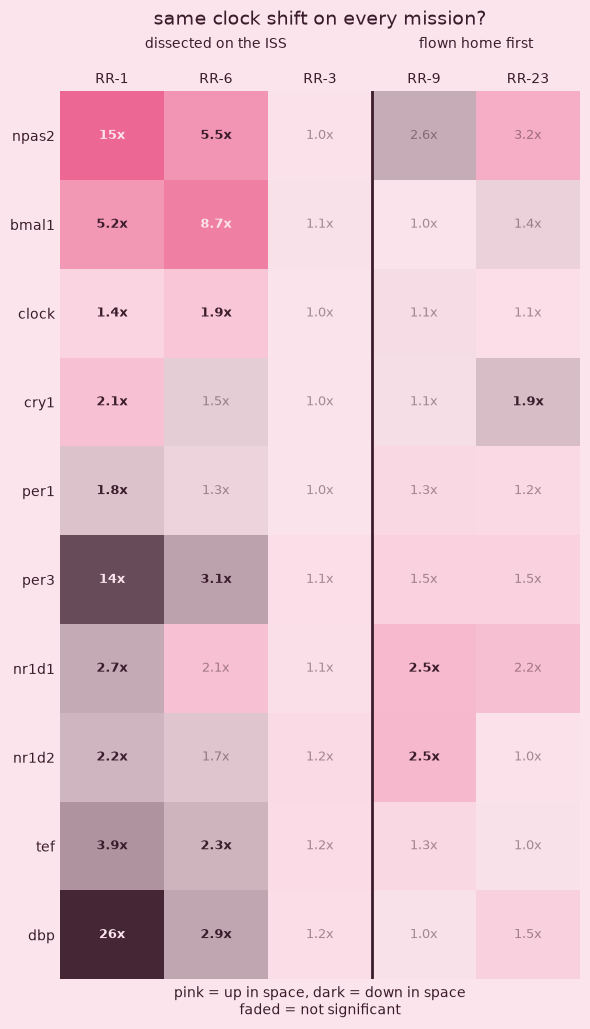

In [4]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list("space", [INK, BLUSH, PINK])
lim = 5

fig, ax = plt.subplots(figsize=(6, 10.7), facecolor=BLUSH)
ax.set_facecolor(BLUSH)
ax.imshow(fc.clip(-lim, lim).fillna(0), cmap=cmap, vmin=-lim, vmax=lim, aspect="auto")

for i, g in enumerate(clock):
    for j, n in enumerate(fc.columns):
        f, p = fc.loc[g, n], padj.loc[g, n]
        if pd.isna(f):
            continue
        dark = abs(f) > lim * 0.55
        ax.text(j, i, f"{2 ** abs(f):.0f}x" if abs(f) >= 3.3 else f"{2 ** abs(f):.1f}x",
                ha="center", va="center", fontsize=9,
                color=BLUSH if dark else INK,
                fontweight="bold" if p < 0.05 else "normal",
                alpha=1 if p < 0.05 else 0.45)

ax.axvline(2.5, color=INK, lw=2)
ax.text(1, -0.95, "dissected on the ISS", ha="center", va="bottom", color=INK, fontsize=10)
ax.text(3.5, -0.95, "flown home first", ha="center", va="bottom", color=INK, fontsize=10)
ax.set_xticks(range(len(fc.columns)), fc.columns, color=INK)
ax.set_yticks(range(len(clock)), [g.lower() for g in clock], color=INK)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("same clock shift on every mission?", color=INK, fontsize=14, pad=48)
ax.set_xlabel("pink = up in space, dark = down in space\nfaded = not significant", color=INK, fontsize=10)

plt.tight_layout()
plt.subplots_adjust(bottom=0.08)
plt.savefig("clock_missions.png", dpi=200, facecolor=BLUSH)
plt.show()

# Cell 5  //  Does RR-1 Replicate?

Takes all 184 genes that changed in RR-1 and checks whether they move the same direction on each other mission. If space did nothing consistent, you'd expect about 50% just by chance.

In [5]:
rr1 = runs["RR-1"]
hits = rr1[(rr1["fc"].abs() > 1) & (rr1["padj"] < 0.05)]
print(f"RR-1 found {len(hits)} changed genes. How many move the same way on the other missions?\n")
for name, m in runs.items():
    if name == "RR-1":
        continue
    both = hits.join(m, rsuffix="_other", how="inner")
    same = (np.sign(both["fc"]) == np.sign(both["fc_other"])).sum()
    same_sig = ((np.sign(both["fc"]) == np.sign(both["fc_other"])) & (both["padj_other"] < 0.05)).sum()
    print(f"{name:<6} same direction: {same}/{len(both)} ({same / len(both):.0%})   "
          f"same direction and significant there too: {same_sig}")

RR-1 found 184 changed genes. How many move the same way on the other missions?

RR-6   same direction: 137/175 (78%)   same direction and significant there too: 59
RR-3   same direction: 85/175 (49%)   same direction and significant there too: 0
RR-9   same direction: 42/169 (25%)   same direction and significant there too: 2
RR-23  same direction: 73/173 (42%)   same direction and significant there too: 15


/tmp/ipykernel_32717/3093605007.py:7: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  both = hits.join(m, rsuffix="_other", how="inner")


## What the Replication Found

- **RR-6 repeats RR-1.** 78% of RR-1's changed genes move the same way, and 59 are significant there too. The clock pattern matches: Npas2 and Bmal1 up, Dbp, Per3 and Tef down.
- **RR-9 and RR-23 do not.** Those mice were flown home alive and dissected on Earth days later. The clock shift is gone, and in RR-9 only 25% of genes go the same way, so it's partly reversed. RR-9's ground controls were also run a year later because of Hurricane Irma.
- **RR-3 found nothing at all.** Zero changed genes overall, not just clock genes. It's also a different mouse strain (BALB/c), so it can't tell us much either way.

So the honest claim gets sharper: the body clock shift shows up in mice **euthanized aboard the ISS**, and isn't seen in mice brought back to Earth first. Either the clock resets within a few days of landing, or something about on-orbit dissection (like the time of day it happened) is part of the signal. These five studies can't tell those two apart. Strain, sex and age also differ between missions, so treat this as a strong clue, not proof.

Data: NASA Space Biology Open Science Data Repository (OSDR), studies OSD-48, OSD-245, OSD-137, OSD-242 and OSD-463, accessed 2026-10-26 from https://registry.opendata.aws/nasa-osdr.